Device: cuda
Image: 000098.jpg


preprocessor_config.json:   0%|          | 0.00/382 [00:00<?, ?B/s]

c:\Users\yatha\Desktop\autonomous-driving-perception\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yatha\.cache\huggingface\hub\models--Intel--dpt-hybrid-midas. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/9.88k [00:00<?, ?B/s]

c:\Users\yatha\Desktop\autonomous-driving-perception\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yatha\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  490MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  490MB            

model.safetensors: downloading bytes:           |  0.00B            

Depth map shape: (376, 1241)
Relative depth range: -110.43063354492188 to 1628.884521484375


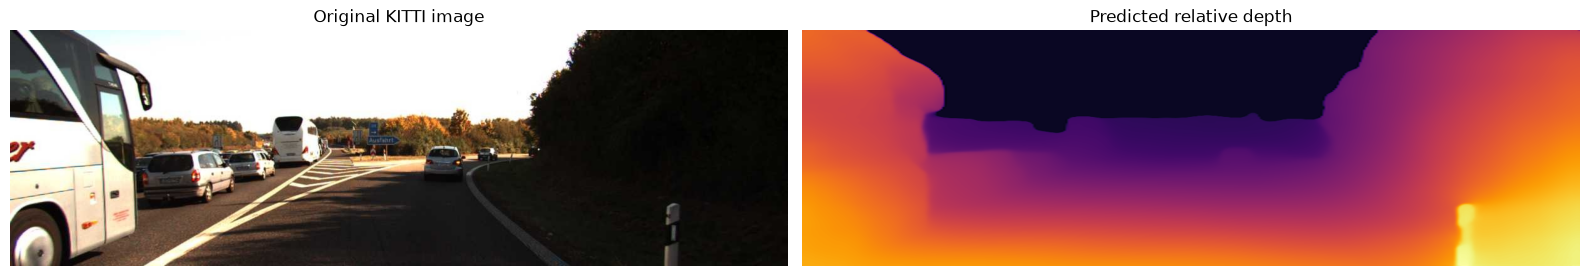

In [2]:

from pathlib import Path
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import DPTImageProcessor, DPTForDepthEstimation
from PIL import Image

# Project paths
project_dir = Path.cwd().parent
val_dir = project_dir / "data" / "kitti_yolo" / "images" / "val"

images = sorted(val_dir.glob("*.jpg"))
if not images:
    raise FileNotFoundError(f"No validation images found in {val_dir}")

image_path = images[0]

# Load image as RGB
image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise ValueError(f"Could not read image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
pil_image = Image.fromarray(image_rgb)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Image:", image_path.name)

# Load pretrained monocular depth model
model_name = "Intel/dpt-hybrid-midas"
processor = DPTImageProcessor.from_pretrained(model_name)
model = DPTForDepthEstimation.from_pretrained(model_name)
model = model.to(device).eval()

# Predict depth
inputs = processor(images=pil_image, return_tensors="pt")
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)
    predicted_depth = outputs.predicted_depth

# Resize prediction to original image dimensions
depth = torch.nn.functional.interpolate(
    predicted_depth.unsqueeze(1),
    size=(image_rgb.shape[0], image_rgb.shape[1]),
    mode="bicubic",
    align_corners=False,
).squeeze().cpu().numpy()

# Normalize only for visualization
depth_min, depth_max = depth.min(), depth.max()
depth_visual = (depth - depth_min) / (depth_max - depth_min + 1e-8)

print("Depth map shape:", depth.shape)
print("Relative depth range:", float(depth_min), "to", float(depth_max))

# Display image and depth map
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original KITTI image")
axes[0].axis("off")

axes[1].imshow(depth_visual, cmap="inferno")
axes[1].set_title("Predicted relative depth")
axes[1].axis("off")

plt.tight_layout()
plt.show()


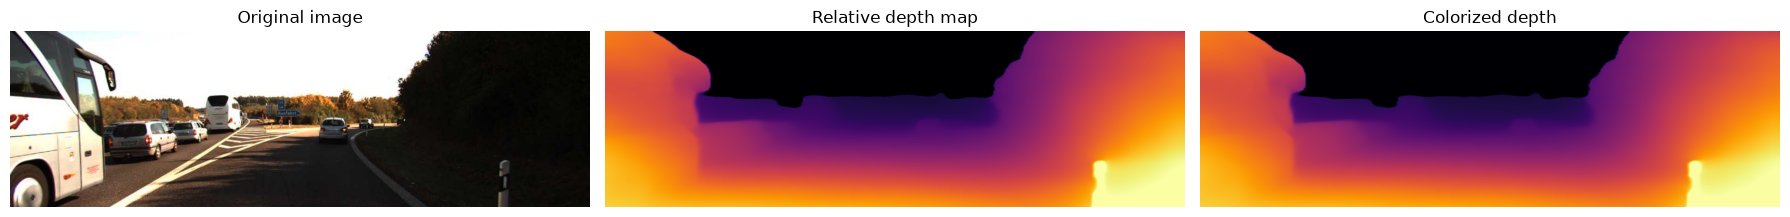

Saved depth visualization to: c:\Users\yatha\Desktop\autonomous-driving-perception\runs\depth_estimation\kitti_depth_visualization.png


In [3]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# Normalize depth robustly, reducing the effect of extreme values
low, high = np.percentile(depth, [2, 98])
depth_clipped = np.clip(depth, low, high)

depth_normalized = (
    (depth_clipped - low) / (high - low + 1e-8)
)

# Apply a color map for easier interpretation
depth_uint8 = (depth_normalized * 255).astype(np.uint8)
depth_colored = cv2.applyColorMap(
    depth_uint8, cv2.COLORMAP_INFERNO
)
depth_colored = cv2.cvtColor(
    depth_colored, cv2.COLOR_BGR2RGB
)

# Save the visualization
project_dir = Path.cwd().parent
output_dir = project_dir / "runs" / "depth_estimation"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "kitti_depth_visualization.png"
cv2.imwrite(
    str(output_path),
    cv2.cvtColor(depth_colored, cv2.COLOR_RGB2BGR)
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original image")

axes[1].imshow(depth_normalized, cmap="inferno")
axes[1].set_title("Relative depth map")

axes[2].imshow(depth_colored)
axes[2].set_title("Colorized depth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Saved depth visualization to:", output_path)
